<a href="https://colab.research.google.com/github/d3m1d0s/FoML_projects/blob/main/project_2/bank_fraud_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://github.com/d3m1d0s/FoML_projects/blob/main/project_2/bank_fraud_classification.ipynb" target="_parent"><img src="https://img.shields.io/badge/View%20on-GitHub-181717?logo=github" alt="View on GitHub"/></a>

**Fundamentals of Machine Learning, Project 2**

### Classification: Bank Account Fraud

Author: Demid Ostiakov (OST0059)  
Dataset: [Bank Account Fraud Dataset Suite, NeurIPS 2022 (Kaggle)](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022), file `Base.csv`

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/d3m1d0s/FoML_projects/main/project_2/Base.csv.zip"

df = pd.read_csv(DATA_URL)
df.shape

(1000000, 32)

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> First Look at the Data </font></h2>
</div>

Display the first and last 10 rows of the dataset.

In [3]:
# show all columns instead of hiding the middle ones
pd.set_option("display.max_columns", None)

display(df.head(10))

display(df.tail(10))

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0
5,0,0.6,0.294840,-1,369,30,0.024232,-1.232556,AD,1204,11556.955514,7506.951276,6482.924037,705,5,CB,134,1,BE,1,1,30,0,200.0,0,INTERNET,6.987316,linux,1,1,0,0
6,0,0.2,0.773085,22,4,40,0.006919,-0.544676,AB,1998,11723.993606,7864.277144,6338.799156,28,8,CA,72,1,BC,1,1,1,0,200.0,0,INTERNET,28.199923,x11,1,1,0,0
7,0,0.8,0.153880,-1,103,40,0.045122,-1.101184,AB,1548,4999.555801,4526.861667,6426.790817,6,7,CA,163,0,BE,1,1,25,1,200.0,0,INTERNET,11.234264,other,1,1,0,0
8,0,0.3,0.523655,21,2,30,0.035206,-0.955737,AB,1781,6979.994002,4335.685346,6624.957942,2,10,CA,35,0,BC,1,0,2,0,200.0,0,INTERNET,5.329387,other,1,1,0,0
9,0,0.8,0.834475,-1,134,20,0.017245,-1.356393,AD,3113,7549.992086,6273.922110,6312.998835,14,20,CA,201,1,BD,1,1,15,0,1500.0,0,INTERNET,4.103970,other,1,1,0,0


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
999990,0,0.7,0.129088,-1,111,30,0.029064,-1.123643,AB,1450,793.303314,2341.492693,3036.351678,7,4,CA,266,0,BB,0,1,1,0,1500.0,0,INTERNET,3.481792,linux,1,1,0,7
999991,0,0.6,0.730618,-1,362,40,0.022143,96.775940,AB,669,5267.312130,2213.491925,3028.221403,41,4,CA,344,1,BC,0,1,27,0,1500.0,0,INTERNET,5.049117,other,1,1,0,7
999992,0,0.9,0.432945,55,0,30,0.015941,-0.652537,AB,384,4001.079918,3624.941984,3106.809780,8,16,CA,127,1,BC,0,1,28,0,200.0,0,INTERNET,1.400871,linux,1,1,0,7
999993,0,0.8,0.532661,12,15,20,0.016189,-0.694345,AC,403,4099.481370,3296.817128,3134.518780,9,12,CA,248,0,BF,1,1,-1,0,1500.0,0,INTERNET,5.755127,other,1,1,0,7
999994,0,0.9,0.046317,-1,132,50,0.035818,-1.504382,AD,576,2948.105341,2272.822287,3112.832944,744,1,CA,185,1,BA,0,1,1,0,200.0,0,INTERNET,3.632310,linux,0,1,0,7
999995,0,0.8,0.124690,-1,143,30,0.051348,-0.826239,AB,530,6732.602414,3010.048099,3095.754245,42,8,CA,305,1,BB,1,1,31,0,1500.0,0,INTERNET,16.967770,other,0,1,0,7
999996,0,0.9,0.824544,-1,193,30,0.009591,0.008307,AC,408,1574.293294,2716.495767,4286.089050,0,5,CA,235,0,BA,1,1,-1,1,1000.0,0,INTERNET,1.504109,macintosh,0,1,0,7
999997,0,0.8,0.140891,-1,202,10,0.059287,50.609995,AA,749,1258.864938,3601.322892,3103.891664,2,3,CA,195,1,BE,0,1,31,0,200.0,0,INTERNET,16.068595,other,0,1,0,7
999998,0,0.9,0.002480,52,3,30,0.023357,-1.313387,AB,707,7048.137128,6521.395012,3068.265084,7,8,CA,148,0,BD,0,1,1,0,200.0,0,INTERNET,1.378683,linux,1,1,0,7
999999,0,0.6,0.993391,-1,174,30,0.020422,14.942456,AA,655,3737.076479,3135.788094,3051.003293,14,8,CA,100,1,BB,0,1,15,1,200.0,0,INTERNET,1.947926,other,1,1,0,7


Each row is one application to open a bank account, together with a label that says whether the application was fraudulent.

According to the dataset's Kaggle page, the data are synthetic. They were generated from a real, present-day fraud detection dataset, and to protect the applicants the authors added noise, encoded some features and trained a generative model on the result. `Base.csv` is the base dataset of a suite of six. It has a `month` column, which allows an evaluation over time, and three protected attributes: age group, employment status and income.

The first 10 rows all have `month` 0 and the last 10 all have `month` 7, so the file may be ordered by month. Twenty rows cannot prove this for a million, so the order of the file is checked in the next section. If it is confirmed, a split by row position would be a split by time, and it has to be decided on purpose whether the data are split by month or at random. All 20 rows have `fraud_bool` 0.

Column descriptions, based on the data card of `Base.csv` on the dataset's Kaggle page. Notes in brackets come from the authors' datasheet, which is linked from the Kaggle page.
- `fraud_bool`: fraud label, 1 if the application is fraudulent and 0 if it is legitimate.
- `income`: annual income of the applicant in quantiles, between 0 and 1.
- `name_email_similarity`: similarity between the email and the applicant's name, between 0 and 1. Higher values mean higher similarity.
- `prev_address_months_count`: number of months at the applicant's previous registered address, if there is one. -1 is a missing value.
- `current_address_months_count`: number of months at the currently registered address. -1 is a missing value.
- `customer_age`: age of the applicant in bins per decade (20 to 29 is stored as 20).
- `days_since_request`: number of days passed since the application was done.
- `intended_balcon_amount`: initial transferred amount for the application. (Datasheet: negative values are missing values.)
- `payment_type`: credit payment plan type, 5 anonymised values.
- `zip_count_4w`: number of applications within the same zip code in the last 4 weeks.
- `velocity_6h`, `velocity_24h`, `velocity_4w`: average number of applications per hour in the last 6 hours, 24 hours and 4 weeks.
- `bank_branch_count_8w`: number of applications in the selected bank branch in the last 8 weeks.
- `date_of_birth_distinct_emails_4w`: number of emails for applicants with the same date of birth in the last 4 weeks.
- `employment_status`: employment status of the applicant, 7 anonymised values.
- `credit_risk_score`: internal score of application risk.
- `email_is_free`: domain of the application email, free or paid.
- `housing_status`: current residential status of the applicant, 7 anonymised values.
- `phone_home_valid`, `phone_mobile_valid`: validity of the provided home phone and mobile phone.
- `bank_months_count`: age of the previous account in months, if the applicant held one. -1 is a missing value.
- `has_other_cards`: whether the applicant has other cards from the same banking company.
- `proposed_credit_limit`: credit limit proposed by the applicant.
- `foreign_request`: whether the origin country of the request is different from the bank's country.
- `source`: online source of the application, browser (INTERNET) or mobile app (APP).
- `session_length_in_minutes`: length of the user session on the banking website in minutes. (Datasheet: -1 is a missing value.)
- `device_os`: operating system of the device that made the request: Windows, Macintosh, Linux, X11 or other.
- `keep_alive_session`: user option on session logout.
- `device_distinct_emails_8w`: number of distinct emails on the banking website from the used device in the last 8 weeks. (Datasheet: -1 is a missing value.)
- `device_fraud_count`: number of fraudulent applications with the used device.
- `month`: month in which the application was made, from 0 to 7.

Missing values according to the documentation:
- The data card names -1 as a missing value in three columns: `prev_address_months_count`, `current_address_months_count` and `bank_months_count`.
- The datasheet names a missing value in three more columns: -1 in `session_length_in_minutes` and `device_distinct_emails_8w`, and any negative value in `intended_balcon_amount`. The data card does not mention missing values for these three.
- For all other columns, neither source mentions a missing value.

The datasheet lists `payment_type`, `employment_status`, `housing_status`, `source` and `device_os` as categorical, and the other columns as numeric or binary. It also says that key categorical variables were label encoded to improve privacy. Neither source gives the categories an order.

Both sources give a value range for most numeric columns, and the two do not always agree. These ranges are not copied here, because they are compared with the data in the next section.

The descriptions explain most of what looks unusual in the first and last rows:
- Missing values are stored as numbers. In `prev_address_months_count` 13 of the 20 rows shown hold -1, and in `bank_months_count` 2 of them. In `intended_balcon_amount` every negative value is a missing value according to the datasheet, and most of the 20 rows are negative. How many values are missing in each column is counted in the next section.
- `income` and `customer_age` are not exact values. Income is given in quantiles and age in decades, so both are ordered groups with only a few different values.
- Not every column describes the applicant. The three velocity columns, `zip_count_4w`, `bank_branch_count_8w` and `date_of_birth_distinct_emails_4w` describe how many applications arrived around the same time, from the same zip code, at the same branch or with the same date of birth. This fits what the rows show: `velocity_4w` is around 6,000 to 6,700 in the first rows and mostly around 3,000 in the last ones, so it depends on when the application was made.
- `payment_type`, `employment_status` and `housing_status` hold anonymised codes such as AA, CA or BC, so their categories cannot be interpreted by name.

Some things cannot be settled from the descriptions and 20 rows, and are checked in the next section:
- `device_fraud_count` is 0 and `source` is INTERNET in every row shown, so these columns may hardly vary.
- The value ranges of the data card do not hold exactly. `intended_balcon_amount` should range from -1 to 108, but the rows above already contain -1.49 and -1.86.

Check the basic information about the DataFrame.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

The dataset has 1,000,000 rows and 32 columns. `info()` reports no missing values, but it cannot see them here, because they are stored as -1 or as negative numbers.

The dtype only says how a column is stored, not what it means. Read together with the descriptions:
- Five columns are stored as text and are categories, for which no order is documented: `payment_type`, `employment_status`, `housing_status`, `source` and `device_os`. They need encoding before modelling.
- Six integer columns are yes/no flags by their description, and the rows above show no other values than 0 and 1 in them: `email_is_free`, `phone_home_valid`, `phone_mobile_valid`, `has_other_cards`, `foreign_request` and `keep_alive_session`. Whether they really take only these two values is checked in the next section.
- `income` and `customer_age` are numbers, but they stand for ordered groups.
- `month` is a time index, not a measurement.
- The remaining numeric columns are counts, scores, amounts and durations.

The target is `fraud_bool`. It is stored as an integer, 1 for a fraudulent application and 0 for a legitimate one, and it stays that way, because the models expect a numeric target and the mean of a 0/1 column is directly the share of frauds. The remaining 31 columns are possible inputs. Whether all of them are used is decided later.

Check how the applications are divided between the two classes of the target `fraud_bool`.

In [5]:
target_counts = pd.DataFrame({
    "Applications": df["fraud_bool"].value_counts(),
    "Share (%)": (df["fraud_bool"].value_counts(normalize=True) * 100).round(2),
})

display(target_counts)

,Applications,Share (%)
fraud_bool,,
0,988971,98.9
1,11029,1.1


Only 11,029 of the 1,000,000 applications are fraudulent, which is 1.1%. The classes are extremely imbalanced.

A model that marks every application as legitimate would be right in 98.9% of the cases and would not find a single fraud. Accuracy therefore says almost nothing here, and a high accuracy alone cannot be taken as a sign of a good model.

The evaluation has to look at the two kinds of errors separately: how many of the frauds a model finds, and how many legitimate applications it flags wrongly. The exact metric is chosen before the first model is trained. Because there are so few frauds, every part of a later split has to be checked for how many of them it still contains.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Checking the Data Against the Descriptions </font></h2>
</div>

The first look left several points open. They are checked here on all rows: the order of the file, duplicates, the number of different values and the value range of every numeric column, the values that stand for missing information, and the categories of the text columns.

First the rows: whether the file is ordered by month, whether any row appears more than once, and how many applications each month has.

In [6]:
print("Rows ordered by month:", df["month"].is_monotonic_increasing)
print("Fully duplicated rows:", df.duplicated().sum())

month_counts = df["month"].value_counts().sort_index().rename("Applications").to_frame()

display(month_counts.T)

Rows ordered by month: True
Fully duplicated rows: 0


month,0,1,2,3,4,5,6,7
Applications,132440,127620,136979,150936,127691,119323,108168,96843


The file is ordered by month: `month` never decreases from the first row to the last. A split by row position would therefore be a split by time. A random split has to shuffle the rows, and a split by time can simply use the `month` column.

No row appears twice, so nothing has to be removed.

The months are not equally large. Month 3 has the most applications (150,936) and month 7 the fewest (96,843), and the last two months are the two smallest. Every month still has close to 100,000 applications or more, so no month is too small to work with.

Next the numeric columns. The table shows how many different values each column has and its smallest and largest value, next to the ranges given on the data card and in the datasheet. Where a source gives no range, the cell is empty.

In [7]:
# value ranges from the data card of Base.csv on Kaggle
DATA_CARD_RANGES = {
    "income": (0, 1),
    "name_email_similarity": (0, 1),
    "prev_address_months_count": (-1, 380),
    "current_address_months_count": (-1, 406),
    "days_since_request": (0, 78),
    "intended_balcon_amount": (-1, 108),
    "zip_count_4w": (1, 5767),
    "velocity_6h": (-211, 24763),
    "velocity_24h": (1329, 9527),
    "velocity_4w": (2779, 7043),
    "bank_branch_count_8w": (0, 2521),
    "date_of_birth_distinct_emails_4w": (0, 42),
    "credit_risk_score": (-176, 387),
    "bank_months_count": (-1, 31),
    "proposed_credit_limit": (200, 2000),
    "session_length_in_minutes": (-1, 107),
    "device_distinct_emails_8w": (0, 3),
    "device_fraud_count": (0, 1),
    "month": (0, 7),
}

# value ranges from the authors' datasheet
DATASHEET_RANGES = {
    "income": (0.1, 0.9),
    "name_email_similarity": (0, 1),
    "prev_address_months_count": (-1, 380),
    "current_address_months_count": (-1, 429),
    "customer_age": (10, 90),
    "days_since_request": (0, 79),
    "intended_balcon_amount": (-16, 114),
    "zip_count_4w": (1, 6830),
    "velocity_6h": (-175, 16818),
    "velocity_24h": (1297, 9586),
    "velocity_4w": (2825, 7020),
    "bank_branch_count_8w": (0, 2404),
    "date_of_birth_distinct_emails_4w": (0, 39),
    "credit_risk_score": (-191, 389),
    "bank_months_count": (-1, 32),
    "proposed_credit_limit": (200, 2000),
    "session_length_in_minutes": (-1, 107),
    "device_distinct_emails_8w": (-1, 2),
    "device_fraud_count": (0, 1),
    "month": (0, 7),
}

numeric_cols = df.select_dtypes("number").columns

overview = pd.DataFrame({
    "Distinct values": df[numeric_cols].nunique(),
    "Min": df[numeric_cols].min(),
    "Max": df[numeric_cols].max(),
})


def add_documented_range(source, ranges):
    low = pd.Series({col: limits[0] for col, limits in ranges.items()}).reindex(overview.index)
    high = pd.Series({col: limits[1] for col, limits in ranges.items()}).reindex(overview.index)
    overview[f"Range in {source}"] = [
        f"{ranges[col][0]} to {ranges[col][1]}" if col in ranges else "" for col in overview.index
    ]
    overview[f"Outside {source}"] = (overview["Min"] < low) | (overview["Max"] > high)


add_documented_range("data card", DATA_CARD_RANGES)
add_documented_range("datasheet", DATASHEET_RANGES)

display(overview.round(2))

,Distinct values,Min,Max,Range in data card,Outside data card,Range in datasheet,Outside datasheet
fraud_bool,2,0.00,1.00,,False,,False
income,9,0.10,0.90,0 to 1,False,0.1 to 0.9,False
name_email_similarity,998861,0.00,1.00,0 to 1,False,0 to 1,False
prev_address_months_count,374,-1.00,383.00,-1 to 380,True,-1 to 380,True
current_address_months_count,423,-1.00,428.00,-1 to 406,True,-1 to 429,False
customer_age,9,10.00,90.00,,False,10 to 90,False
days_since_request,989330,0.00,78.46,0 to 78,True,0 to 79,False
intended_balcon_amount,994971,-15.53,112.96,-1 to 108,True,-16 to 114,False
zip_count_4w,6306,1.00,6700.00,1 to 5767,True,1 to 6830,False
velocity_6h,998687,-170.60,16715.57,-211 to 24763,False,-175 to 16818,False


The six yes/no flags are confirmed: `email_is_free`, `phone_home_valid`, `phone_mobile_valid`, `has_other_cards`, `foreign_request` and `keep_alive_session` each have exactly two values, 0 and 1.

`device_fraud_count` has a single value: it is 0 in all rows, although the data card gives a range from 0 to 1. A column that never changes cannot help to tell fraud from legitimate applications. It is removed in the data preparation, together with the other decisions about which columns the models get.

Some numeric columns have only a few different values:
- `income` (9 values from 0.1 to 0.9) and `customer_age` (9 values from 10 to 90), which confirms that both are bins.
- `proposed_credit_limit` has only 12 different values, so it behaves like a small set of fixed limits, not like a freely chosen amount.
- `device_distinct_emails_8w` has 4 values from -1 to 2.

The data go outside the range of the data card in ten columns:
- In most of them the difference is small, for example a maximum of 383 months instead of 380 in `prev_address_months_count`, 389 instead of 387 in `credit_risk_score` or 32 months instead of 31 in `bank_months_count`.
- It is larger in `current_address_months_count` (428 months instead of 406), `zip_count_4w` (6,700 instead of 5,767), `proposed_credit_limit` (190 to 2,100 instead of 200 to 2,000) and `intended_balcon_amount` (-15.53 to 112.96 instead of -1 to 108).
- `device_distinct_emails_8w` starts at -1, while the data card gives 0 as its lowest value.

Against the datasheet, only two columns go outside: `prev_address_months_count` (383 months instead of 380) and `proposed_credit_limit` (190 to 2,100 instead of 200 to 2,000).

The datasheet describes this file better. In most columns its limits lie right at the smallest and largest value of the data, for example 1 to 6,830 for `zip_count_4w` (data: 1 to 6,700) or -175 to 16,818 for `velocity_6h` (data: -170.60 to 16,715.57). The limits of the data card are too narrow in ten columns and much too wide in others: for `velocity_6h` it allows values up to 24,763. Why the two sources differ is not documented. Where they disagree, the datasheet is taken as the more reliable one.

Neither of the two remaining differences looks like wrong data. A previous address held for 383 months and a credit limit of 190 or 2,100 lie just beside the documented limits, and both are possible values. The negative values are looked at next. No rows are removed.

Missing values are stored as -1 or as negative numbers, so the negative values of every numeric column are counted. The table lists only the columns that contain any, with the number of different negative values and with what the documentation says about missing values in that column.

In [8]:
# what the documentation says about missing values, column by column
DOCUMENTED_MISSING = {
    "prev_address_months_count": "data card: -1",
    "current_address_months_count": "data card: -1",
    "bank_months_count": "data card: -1",
    "intended_balcon_amount": "datasheet: negative values",
    "session_length_in_minutes": "datasheet: -1",
    "device_distinct_emails_8w": "datasheet: -1",
}

negative_values = df[numeric_cols].where(df[numeric_cols] < 0)
negative_counts = negative_values.count()

negative_summary = pd.DataFrame({
    "Negative values": negative_counts,
    "Distinct negative values": negative_values.nunique(),
    "Equal to -1": (df[numeric_cols] == -1).sum(),
    "Negative share (%)": (negative_counts / len(df) * 100).round(2),
    "Documented as missing": [DOCUMENTED_MISSING.get(col, "no") for col in numeric_cols],
})

display(negative_summary[negative_summary["Negative values"] > 0])

,Negative values,Distinct negative values,Equal to -1,Negative share (%),Documented as missing
prev_address_months_count,712920,1,712920,71.29,data card: -1
current_address_months_count,4254,1,4254,0.43,data card: -1
intended_balcon_amount,742523,737834,0,74.25,datasheet: negative values
velocity_6h,44,44,0,0.00,no
credit_risk_score,14445,164,488,1.44,no
bank_months_count,253635,1,253635,25.36,data card: -1
session_length_in_minutes,2015,1,2015,0.20,datasheet: -1
device_distinct_emails_8w,359,1,359,0.04,datasheet: -1


Eight columns contain negative values. For six of them the documentation names a missing value:
- The data card and the datasheet both name -1 in `prev_address_months_count` (71.29% of the rows), `bank_months_count` (25.36%) and `current_address_months_count` (0.43%).
- Only the datasheet names a missing value in `intended_balcon_amount` (any negative value, 74.25%), `session_length_in_minutes` (-1, 0.20%) and `device_distinct_emails_8w` (-1, 0.04%).

In five of the six columns the data look exactly as documented: there is one single negative value, -1. This also holds for the two columns where only the datasheet speaks of missing values. A session length or a number of emails cannot be negative, so a single -1 in such a column behaves like a code and not like a measurement, which supports the datasheet.

`intended_balcon_amount` does not fit this pattern. Its 742,523 negative values are almost all different from each other (737,834 different values), none of them equals -1, and the table of ranges shows that they go down to -15.53. They are not one code. That they stand for missing values is stated only in the datasheet, and this table cannot confirm it. One possible explanation is a -1 code that was blurred when the data were generated: the Kaggle page says that noise was added for privacy, and on the data card the range of this column starts at -1. This is only an assumption. Before the column is treated, its negative values are therefore examined more closely in the section on missing values.

In the other two columns the negative values are not documented as missing:
- `credit_risk_score` has 14,445 negative values (1.44%) with 164 different values, and both sources give it a range that starts far below zero. These are ordinary scores, including the 488 that equal -1. So -1 must not be read as missing in every column, only in the documented ones.
- `velocity_6h` has 44 negative values, all different. A negative average number of applications has no natural meaning, but both sources include negative values in the range of this column, and 44 rows out of a million are too few to matter. They are left as they are.

For the models this means that missing values cannot be handled by removing rows. `prev_address_months_count` alone is missing in 71.29% of the applications, so less than a third of the rows would be left. Filling this column with a typical value would invent most of its content. The descriptions also suggest that a missing value can carry meaning: a previous address is recorded only if applicable and a previous account only if held, so a missing value may mean that there is none. Whether an application has a missing value could therefore be useful information for a model. How each column is treated is decided in the section on missing values.

Finally the five text columns: which categories they contain and how often each one occurs.

In [9]:
text_cols = df.select_dtypes(exclude="number").columns

category_counts = pd.concat({
    col: pd.DataFrame({
        "Applications": df[col].value_counts(),
        "Share (%)": (df[col].value_counts(normalize=True) * 100).round(2),
    })
    for col in text_cols
})

display(category_counts)

Applications  Share (%)
payment_type      AB               370554      37.06
                  AA               258249      25.82
                  AC               252071      25.21
                  AD               118837      11.88
                  AE                  289       0.03
employment_status CA               730252      73.03
                  CB               138288      13.83
                  CF                44034       4.40
                  CC                37758       3.78
                  CD                26522       2.65
                  CE                22693       2.27
                  CG                  453       0.05
housing_status    BC               372143      37.21
                  BB               260965      26.10
                  BA               169675      16.97
                  BE               169135      16.91
                  BD                26161       2.62
                  BF                 1669       0.17
                  BG                  252       0.03
source            INTERNET         992952      99.30
                  TELEAPP            7048       0.70
device_os         other            342728      34.27
                  linux            332712      33.27
                  windows          263506      26.35
                  macintosh         53826       5.38
                  x11                7228       0.72

The number of categories matches the descriptions in every column: 5 payment types, 7 employment statuses, 7 housing statuses, 2 sources and 5 operating systems.

The values of `device_os` match as well. In `source` the second value is TELEAPP, while the data card calls it APP. The meaning stays the same: an application that did not come through the browser.

The categories are very unevenly filled:
- `source` is almost constant: 99.30% of the applications are INTERNET and only 7,048 are TELEAPP.
- `employment_status` is dominated by CA with 73.03%.
- Each of the three anonymised columns has a very rare category: AE in `payment_type` (289 applications, 0.03%), CG in `employment_status` (453, 0.05%) and BG in `housing_status` (252, 0.03%). BF in `housing_status` is also small (1,669, 0.17%).

With a fraud share of 1.1%, a category with only a few hundred applications can be expected to hold only a handful of frauds, so nothing reliable can be learned about such a category. After a split, a rare category may also be almost absent from one of the parts. The encoding has to work in that case too. The documentation gives none of the five columns an order: the datasheet lists them as categorical and says that key categorical variables were label encoded for privacy. Codes such as AA to AE are therefore only labels, and their alphabetical order cannot be assumed to mean anything. The columns are treated as categories without an order.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> The Task and the Test Set </font></h2>
</div>

The task is a binary classification: from the information in an application, predict whether it is fraudulent (`fraud_bool` = 1). A model gives every application a probability of fraud, and a threshold then turns this probability into a decision.

Such a model is used on applications as they arrive. It is trained on applications whose outcome is already known and then has to judge new ones. The data were recorded over eight months and the `month` column says when each application was made, so the evaluation is built the same way: the models are developed on the earlier months and tested on the later ones.

This follows from how the model is used, not from a pattern found in the data. Applications from different months may differ in ways that no table shows in advance, for example in which applications are fraudulent or in how the columns relate to fraud. A random split would put applications from all eight months into both parts. The model would then be tested on months it has already learned from, and it could not be seen how it does on a period that is new to it. A split by time does not need to know what changes between the months. It simply gives the model nothing from the months it is tested on.

The authors of the dataset work the same way. In the paper that is linked from the Kaggle page, they train on the first six months and test on the last two, and call this common practice in fraud detection, because more recent data are closer to what a model meets when it is put into use.

The data are therefore split as follows:
- Months 0 to 5 are the development data. Everything that leads to the final model happens here: the remaining preparation of the data, the comparison of models, the tuning and the choice of the threshold.
- Months 6 and 7 are the test set. It is put aside now and used once at the end, when the model, its settings and the threshold are fixed. The result is reported for the two months together and for each of them separately.

The two sections above looked at all rows, but only at the structure of the file: types, ranges, codes and categories, and the overall share of frauds. From here on, nothing is learned from months 6 and 7 except how many applications and frauds they contain.

In [10]:
TEST_MONTHS = [6, 7]

in_test = df["month"].isin(TEST_MONTHS)
df_dev = df[~in_test].copy()
df_test = df[in_test].copy()

split_summary = pd.DataFrame.from_dict({
    name: {
        "Applications": len(part),
        "Share of all applications (%)": round(len(part) / len(df) * 100, 2),
        "Frauds": part["fraud_bool"].sum(),
        "Fraud share (%)": round(part["fraud_bool"].mean() * 100, 2),
    }
    for name, part in {"Development (months 0 to 5)": df_dev, "Test (months 6 and 7)": df_test}.items()
}, orient="index")

display(split_summary)

,Applications,Share of all applications (%),Frauds,Fraud share (%)
Development (months 0 to 5),794989,79.5,8151,1.03
Test (months 6 and 7),205011,20.5,2878,1.40


The development data hold 794,989 applications (79.5%) with 8,151 frauds, and the test set 205,011 applications (20.5%) with 2,878 frauds. The split was set by months, not by size, but it comes out close to 80 to 20.

The test set is large enough to measure how many frauds a model finds. With 2,878 frauds, one fraud found more or less changes the share of frauds found only by a small fraction of a percentage point.

The share of frauds is not the same in the two parts: 1.03% in the development data and 1.40% in the test set. This is one difference between the earlier and the later months that happens to be visible in a simple count. It says nothing about what else differs.

For comparing results it means that measures which depend on how common fraud is cannot be compared directly between the two parts. Precision is such a measure: among the flagged applications, the share of real frauds is higher when frauds are more common, even if the model behaves exactly the same. The share of frauds that are found and the share of legitimate applications that are flagged are each counted inside one class, so they do not depend on the share of frauds. The difference is not used for any decision, and the threshold is chosen on the development data only.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Validation Inside the Development Data </font></h2>
</div>

To choose between models and between their settings, the candidates have to be compared on data they were not trained on. The test set is not available for this, so the comparison happens inside the development data. It follows the same rule as the test set: a model is never judged on a month it has learned from, and never on a month that lies before its training data.

**Three folds ordered by month.** In each fold the model is trained on all months before the validation month and judged on that month:
- months 0 to 2, judged on month 3,
- months 0 to 3, judged on month 4,
- months 0 to 4, judged on month 5.

This is cross-validation with folds ordered in time, also known as an expanding window or walk-forward validation. Months 1 and 2 are not used as validation months. Their models would be trained on one or two months only, far less than the six months the final model is trained on, so their results would say little about it.

**Five sub-folds in each fold.** A single fit depends partly on chance: on which applications happen to be in the training data, and on the random steps inside some models. To see how large this effect is and to average it out, each fold is repeated five times. The training months are cut into five parts that all keep the same mix of months and the same share of frauds. Each repetition leaves out a different part and trains on the other four. Every repetition is judged on the whole validation month. The part that was left out is not used for judging, because it comes from the training months. The score of a fold is the average of its five repetitions, and the spread between them shows how much of a score is chance.

The five parts are cut with Stratified K-Fold. Stratified K-Fold on all rows at once is not used, because its folds are drawn at random from all months, so every fold would be judged on months that the model has already seen during training.

**Where each is used.** The sub-folds, 15 fits in total, are used to compare models and to check again the best settings found by tuning. During the tuning itself, where many settings are tried one after another, the three folds without sub-folds are used, to keep the running time reasonable.

Preparation steps that learn something from the data, such as scaling, are fitted inside each fit on its training rows only.

The cell below builds the folds and the sub-folds and shows what they contain.

In [11]:
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42
VALIDATION_MONTHS = [3, 4, 5]
SUB_FOLDS = 5

dev_month = df_dev["month"].to_numpy()
dev_fraud = df_dev["fraud_bool"].to_numpy()

# one fold per validation month: train on all earlier months, validate on that month
month_folds = [
    (np.flatnonzero(dev_month < month), np.flatnonzero(dev_month == month))
    for month in VALIDATION_MONTHS
]

# five sub-folds per fold: each leaves out a different fifth of the training rows
part_splitter = StratifiedKFold(n_splits=SUB_FOLDS, shuffle=True, random_state=RANDOM_STATE)
sub_folds = []

for train_rows, valid_rows in month_folds:
    # one label for every combination of month and class, so each part keeps the same mix of both
    month_and_class = dev_month[train_rows] * 2 + dev_fraud[train_rows]
    for kept, left_out in part_splitter.split(train_rows, month_and_class):
        sub_folds.append((train_rows[kept], valid_rows))

fold_summary = pd.DataFrame([
    {
        "Training months": f"0 to {month - 1}",
        "Validation month": month,
        "Training applications": len(train_rows),
        "Training frauds": dev_fraud[train_rows].sum(),
        "Training share of development data (%)": round(len(train_rows) / len(df_dev) * 100, 1),
        "Applications in a sub-fold": len(sub_folds[fold * SUB_FOLDS][0]),
        "Frauds in a sub-fold": dev_fraud[sub_folds[fold * SUB_FOLDS][0]].sum(),
        "Sub-fold share of development data (%)": round(len(sub_folds[fold * SUB_FOLDS][0]) / len(df_dev) * 100, 1),
        "Validation applications": len(valid_rows),
        "Validation frauds": dev_fraud[valid_rows].sum(),
    }
    for fold, (month, (train_rows, valid_rows)) in enumerate(zip(VALIDATION_MONTHS, month_folds))
], index=pd.RangeIndex(1, len(VALIDATION_MONTHS) + 1, name="Fold"))

print("Folds:", len(month_folds), "| sub-folds in total:", len(sub_folds))
display(fold_summary)

Folds: 3 | sub-folds in total: 15


,Training months,Validation month,Training applications,Training frauds,Training share of development data (%),Applications in a sub-fold,Frauds in a sub-fold,Sub-fold share of development data (%),Validation applications,Validation frauds
Fold,,,,,,,,,,
1,0 to 2,3,397039,3896,49.9,317631,3118,40.0,150936,1392
2,0 to 3,4,547975,5288,68.9,438380,4231,55.1,127691,1452
3,0 to 4,5,675666,6740,85.0,540532,5392,68.0,119323,1411


The training sets of the three folds hold 397,039, 547,975 and 675,666 applications, which is 49.9%, 68.9% and 85.0% of the development data. They contain 3,896, 5,288 and 6,740 frauds. The folds are not equally large, because each one adds a month, and the last fold is the closest to the final model.

One sub-fold keeps four of the five parts of its fold's training data: 317,631 of the 397,039 applications in the first fold, with 3,118 of its 3,896 frauds. Measured against the whole development data, the sub-folds hold 40.0%, 55.1% and 68.0%. Even the smallest sub-fold trains on more than 300,000 applications and more than 3,000 frauds.

Every validation month contains enough frauds to compare models: 1,392, 1,452 and 1,411. With more than a thousand frauds in each month, one fraud found more or less changes the share of frauds found only by a small fraction of a percentage point.

The folds still differ from the final situation in three ways:
- **Less training data.** The final model is trained once, on all of months 0 to 5, after the candidate and its settings have been chosen. The models fitted in the folds and sub-folds only serve to measure the candidates and are not used afterwards. The largest fold has 85.0% of it, and its sub-folds 68.0%. If a model improves with more data, the validation scores are somewhat lower than what the final model can reach. The validation scores are therefore used to rank the candidates against each other, all measured under the same conditions. They are not used as an estimate of the score the final model will reach on the test set.
- **Only one month ahead.** Each fold is judged on the month right after its training data. The test set also contains month 7, which lies two months after the end of the training data.
- **Only three months, and sub-folds that overlap.** The five sub-folds of a fold share most of their training data and are judged on the same month. Their spread shows how much a score depends on the training sample and on chance inside the model. It does not show how results change from month to month. For that there are only the three validation months.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Evaluation Metrics </font></h2>
</div>

A model gives every application a probability of fraud, and the bank flags the applications above a threshold. Every flagged legitimate application is a customer who is checked or refused, so the bank can only afford to flag a limited share of them. Within that limit, it wants to catch as many frauds as possible.

**The metric that decides.** Models and their settings are compared by the **recall at a false positive rate of 5%**: the threshold is set so that 5% of the legitimate applications are flagged, and the metric is the share of all frauds that are flagged at that threshold. This is the metric of the dataset's authors. In their paper, which is linked from the Kaggle page, they describe the 5% limit as a requirement that clients in fraud detection typically set, because every wrongly flagged customer is a dissatisfied one who may leave the bank. The limit therefore comes from the use of the model, not from results on this data, and it is fixed here before any model is trained. Using the same metric also makes the results comparable with the paper.

In the validation folds, the threshold is set separately in each validation month, so that 5% of its legitimate applications are flagged. Every candidate is measured under the same rule, and the results serve only to compare them.

**Metrics reported next to it.** They describe the models from other sides. The choice between models is made by the recall at 5%, and these metrics are used to check it. When two candidates are too close to separate by the recall, they can also help to decide between them.
- **ROC-AUC** measures how well a model ranks frauds above legitimate applications over all thresholds. It needs no threshold, so it shows whether a model ranks well in general, not only around the 5% threshold. It is not the deciding metric, because it also covers thresholds that no bank would use.
- **Precision, recall and F1** are computed at the 5% threshold. Recall is the share of all frauds that are flagged, so at this threshold it is the deciding metric itself. Precision is the share of real frauds among the flagged applications. F1 combines the two in one number and is high only when both are high. Precision stays low even for a good model: frauds are only about one in a hundred applications, while 5% of all legitimate applications are flagged, so most flagged applications are legitimate.
- **Accuracy** is the share of all applications that are classified correctly. It is reported only for completeness. The target table in the first look shows that 98.9% of all applications are legitimate, so a model that marks every application as legitimate is already right in 98.9% of them, without finding a single fraud.

**The threshold for the final model.** For the test set, the threshold cannot be taken from the test months, because a bank does not know in advance which new applications are legitimate. It is fixed on the development data only. The test result is then reported in two ways:
- the recall at 5% measured on months 6 and 7, which can be compared with the paper,
- the recall and the actual share of flagged legitimate applications with the threshold fixed on the development data, which is what the bank would see. If the months differ, this share will not be exactly 5%.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Missing Values </font></h2>
</div>

Six columns store missing information as -1 or as negative numbers. Before deciding how to treat them, two questions are answered:
- Does a negative `intended_balcon_amount` really stand for a missing value? Only the datasheet says so, and unlike the other five columns, its negative values are not one code.
- Is a missing value related to fraud? If it is, the fact that a value is missing is information a model can use.

From here on, all analysis uses the development data only (months 0 to 5).

### The negative values of `intended_balcon_amount`

If the negative values stand for a missing amount, they should look like one code that was blurred, and they should be clearly apart from the real amounts. The left plot shows all values, the right one only the values between -3 and 3, with a dashed line at 0. The table compares the negative values with the values of 0 and above.

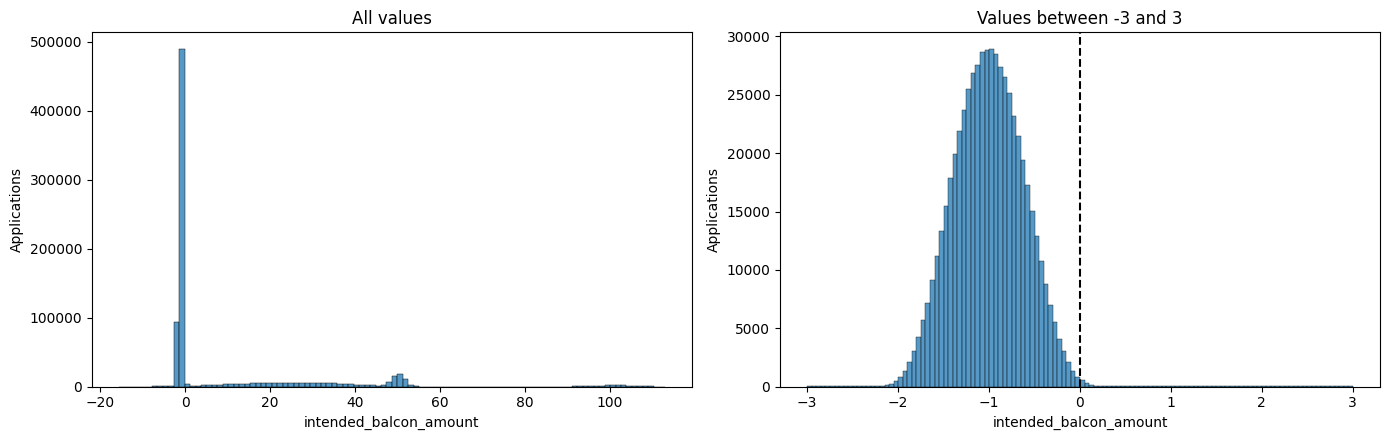

,count,mean,std,min,1%,50%,99%,max,Share of development data (%)
Negative values,585908.0,-1.014,0.445,-15.531,-1.865,-1.005,-0.178,-0.000,73.7
Values of 0 and above,209081.0,36.714,23.188,0.000,1.599,32.608,105.788,112.957,26.3


In [12]:
balcon = df_dev["intended_balcon_amount"]
is_negative = balcon < 0

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(balcon, bins=100, ax=axes[0])
axes[0].set_title("All values")

sns.histplot(balcon[balcon.between(-3, 3)], bins=120, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Values between -3 and 3")

for axis in axes:
    axis.set_xlabel("intended_balcon_amount")
    axis.set_ylabel("Applications")

plt.tight_layout()
plt.show()

balcon_summary = pd.DataFrame({
    "Negative values": balcon[is_negative].describe(percentiles=[0.01, 0.5, 0.99]),
    "Values of 0 and above": balcon[~is_negative].describe(percentiles=[0.01, 0.5, 0.99]),
}).T
balcon_summary["Share of development data (%)"] = [is_negative.mean() * 100, (~is_negative).mean() * 100]

display(balcon_summary.round(3))

The negative values form one narrow pile around -1. Their median is -1.005 and their mean -1.014, with a standard deviation of 0.445, and their 1% and 99% percentiles are -1.865 and -0.178. The right plot shows the same pile as one bell, with almost all values between -2 and 0. A few values lie far below it, down to -15.531.

The amounts of 0 and above look completely different. Their median is 32.608, and in the left plot they are spread thinly from 0 up to above 100, while the negative values form one tall spike near 0. The two groups are mostly apart: between the bell and the real amounts the right plot is almost empty. They do touch at 0, though. The right tail of the bell runs slightly past the dashed line, so some small amounts of 0 and above seem to belong to the bell rather than to the real amounts.

The picture fits a -1 code that was blurred: one value with noise around it, clearly unlike the real amounts. Two things do not fit the cut at 0 exactly, the values far below the bell and the tail just above 0. The interval table below looks at both.

A missing amount should also behave differently from a real one in the rest of the application. Two tables check this: the share of negative amounts for each payment type, and, for each of the other five columns with a documented missing code, how often it is missing among applications with a negative amount and among the others.

In [13]:
payment_summary = pd.DataFrame({
    "Applications": df_dev["payment_type"].value_counts(),
    "Negative amount (%)": is_negative.groupby(df_dev["payment_type"]).mean() * 100,
})

display(payment_summary.round(1))

other_missing_cols = [
    "prev_address_months_count",
    "current_address_months_count",
    "bank_months_count",
    "session_length_in_minutes",
    "device_distinct_emails_8w",
]

missing_together = pd.DataFrame({
    "Missing when the amount is negative (%)": (df_dev.loc[is_negative, other_missing_cols] == -1).mean() * 100,
    "Missing when the amount is 0 or above (%)": (df_dev.loc[~is_negative, other_missing_cols] == -1).mean() * 100,
})

display(missing_together.round(1))

,Applications,Negative amount (%)
payment_type,,
AA,208920,6.4
AB,288182,97.6
AC,198579,99.1
AD,99060,95.1
AE,248,61.7


,Missing when the amount is negative (%),Missing when the amount is 0 or above (%)
prev_address_months_count,70.5,74.3
current_address_months_count,0.5,0.2
bank_months_count,33.4,1.8
session_length_in_minutes,0.2,0.0
device_distinct_emails_8w,0.0,0.0


Whether the amount is negative depends strongly on the payment type. For AA only 6.4% of the amounts are negative, while for AB, AC and AD it is 97.6%, 99.1% and 95.1%. AE lies in between with 61.7%, but it has only 248 applications. So AA is the one common payment type where a real amount is usually given, and the three other common types almost never have one. This fits a missing value that depends on the payment plan: some plans simply come without an intended amount.

One other missing code is clearly more common with a negative amount: `bank_months_count` is missing in 33.4% of the applications with a negative amount and in only 1.8% of the others. `prev_address_months_count` is missing in both groups at a similar, high rate (70.5% and 74.3%), and the remaining three are missing in less than 1% of both groups.

These are the two signs of a missing amount that the next table follows: the payment type and a missing `bank_months_count`.

The tables above split the amounts only at 0, which is the cut from the datasheet. The plots already suggest that this cut does not fit exactly: the bell runs slightly past 0, and a few values lie far below it. The plots only count values, though. They cannot show whether the values at these edges behave like the bell or like the real amounts. The tables below therefore follow the two signs of a missing amount through narrow intervals of the amount, from the lowest values up to the real amounts.

Each row is a group of applications, and the columns show:
- **Applications**: how many applications are in the group.
- **Share with payment type AA (%)**: the percentage of these applications that use payment type AA. One payment type is enough here. AA is the only common payment type whose amounts are mostly real, while AB, AC and AD are almost all negative and behave alike, and AE has too few applications to change the picture. A high share of AA therefore looks like the real amounts, and a low share like the negative ones. The other payment types make up the rest to 100%.
- **Share with `bank_months_count` missing (%)**: the percentage of these applications where `bank_months_count` is -1.

The first table gives these values for the two groups as a whole, all negative amounts and all amounts of 0 and above. They serve as a reference. The second table gives the same values for each interval, so every interval can be compared with the two reference rows.

An interval is written as [a, b): it contains the amounts from a up to b, with a included and b not included. For example, [0, 0.1) contains 0 and every amount above it that is smaller than 0.1.

In [14]:
signs = pd.DataFrame({
    "Applications": 1,
    "Share with payment type AA (%)": (df_dev["payment_type"] == "AA") * 100,
    "Share with bank_months_count missing (%)": (df_dev["bank_months_count"] == -1) * 100,
})

aggregation = {
    "Applications": "sum",
    "Share with payment type AA (%)": "mean",
    "Share with bank_months_count missing (%)": "mean",
}

group = is_negative.map({True: "All negative amounts", False: "All amounts of 0 and above"})
reference_summary = signs.groupby(group).agg(aggregation).rename_axis("Group")

interval = pd.cut(
    balcon,
    [-16, -3, -2.5, -2, -1, -0.5, -0.25, 0, 0.1, 0.25, 0.5, 1, 2, 5, 10, 115],
    right=False,
)
interval_summary = signs.groupby(interval, observed=True).agg(aggregation).rename_axis("Interval of the amount")

display(reference_summary.round(1))
display(interval_summary.round(1))

,Applications,Share with payment type AA (%),Share with bank_months_count missing (%)
Group,,,
All amounts of 0 and above,209081,93.5,1.8
All negative amounts,585908,2.3,33.4


,Applications,Share with payment type AA (%),Share with bank_months_count missing (%)
Interval of the amount,,,
"[-16.0, -3.0)",1170,95.5,1.5
"[-3.0, -2.5)",203,94.6,1.0
"[-2.5, -2.0)",1056,20.0,20.6
"[-2.0, -1.0)",293458,1.8,32.9
"[-1.0, -0.5)",233378,2.1,34.0
"[-0.5, -0.25)",45174,2.7,34.7
"[-0.25, 0.0)",11469,4.1,34.4
"[0.0, 0.1)",817,11.1,32.6
"[0.1, 0.25)",267,41.9,25.1


The reference rows show how the two groups differ as a whole. Among all negative amounts, 2.3% of the applications use payment type AA and 33.4% have `bank_months_count` missing. Among all amounts of 0 and above, it is 93.5% and 1.8%.

The intervals from [-2, -1) up to [0, 0.1) look like the negative amounts as a whole: AA makes up only 1.8% to 11.1% of them, and `bank_months_count` is missing in 32.6% to 34.7%. Below -2.5 and from 0.25 upwards, the intervals look like the amounts of 0 and above: AA makes up 90.5% to 95.5%, and `bank_months_count` is missing in only 1.0% to 3.0%. The two intervals [-2.5, -2) and [0.1, 0.25) lie between the two reference rows, so they are a mix of both kinds of value.

So the change does not happen exactly at 0, but slightly above it. The 817 applications in [0, 0.1) still behave like the negative amounts, and [0.1, 0.25) is a mix. At the low end, the values below -2.5 (1,170 applications in [-16, -3) and 203 in [-3, -2.5)) behave like real amounts, not like the bell. These are the values far below the bell seen in the plots.

Taken together, a negative amount does behave like a missing amount for nearly all values: the bell around -1 is apart from the real amounts, it belongs to payment types other than AA, and it comes with a missing `bank_months_count` far more often. The cut at 0 does not fit at its two edges:
- the values below -2.5 look like real amounts, but the cut marks them as missing,
- the values just above 0, in [0, 0.1) and partly in [0.1, 0.25), belong to the bell, but the cut keeps them as amounts.

Each interval at the edges holds at most 1,170 applications, while the largest intervals of the bell hold 293,458 and 233,378. How the column is treated is not decided yet. The options are:
- to follow the datasheet and treat every negative amount as missing,
- to set the limits where the data change, roughly at -2.5 and 0.25,
- to mix the two: treat every negative amount as missing, as the datasheet says, and add the amounts from 0 up to 0.25, which behave like the bell,
- to keep the values as they are.

With the first three, a separate yes or no column can record that the amount is missing. The choice is made after the next part, which checks how missing values are related to fraud.

### Missing values and fraud

If applications with a missing value are more often, or less often, frauds than the others, then the fact that a value is missing is information a model can use. The table below compares, for each of the six columns, the share of frauds among applications where the value is missing and among those where it is present.

For `intended_balcon_amount`, missing here means negative, as the datasheet says. The edges found above are small, and the second table below looks at them separately.

The table also shows how many applications and frauds stand behind each share. A share computed from a few frauds can change a lot by chance, so it should not be read the same way as one computed from thousands.

In [15]:
is_missing = pd.DataFrame({column: df_dev[column] == -1 for column in other_missing_cols})
is_missing["intended_balcon_amount"] = is_negative

fraud = df_dev["fraud_bool"]

missing_fraud = pd.DataFrame({
    "Missing applications": is_missing.sum(),
    "Missing share (%)": is_missing.mean() * 100,
    "Frauds among missing": is_missing.apply(lambda missing: fraud[missing].sum()),
    "Fraud share when missing (%)": is_missing.apply(lambda missing: fraud[missing].mean() * 100),
    "Fraud share when present (%)": is_missing.apply(lambda missing: fraud[~missing].mean() * 100),
})

print(f"Fraud share in the development data: {fraud.mean() * 100:.2f}%")
display(missing_fraud.round(2))

Fraud share in the development data: 1.03%


,Missing applications,Missing share (%),Frauds among missing,Fraud share when missing (%),Fraud share when present (%)
prev_address_months_count,568423,71.50,7517,1.32,0.28
current_address_months_count,3027,0.38,9,0.30,1.03
bank_months_count,199549,25.10,3064,1.54,0.85
session_length_in_minutes,1513,0.19,13,0.86,1.03
device_distinct_emails_8w,309,0.04,3,0.97,1.03
intended_balcon_amount,585908,73.70,7160,1.22,0.47


For three columns, a missing value goes with clearly more fraud. When `prev_address_months_count` is missing, 1.32% of the applications are frauds, against only 0.28% when it is present. For `bank_months_count` it is 1.54% against 0.85%, and for a negative `intended_balcon_amount` 1.22% against 0.47%. In all three, the missing group lies above the fraud share of the development data (1.03%) and the present group below it. These shares rest on thousands of frauds, so they are not a matter of chance. None of the three large columns goes with less fraud when a value is missing.

For the other three columns, there is too little to say anything. `current_address_months_count`, `session_length_in_minutes` and `device_distinct_emails_8w` are missing in 3,027, 1,513 and 309 applications, with only 9, 13 and 3 frauds among them. Their fraud shares when missing (0.30%, 0.86% and 0.97%) are lower than when present, but with so few frauds they could change a lot by chance.

For the three large columns, the fact that a value is missing is information about fraud, so the treatment has to keep it. A tree model can find it by itself while the -1 code stays in the column. If the missing values are filled instead, for example with the median, a separate yes or no column has to record where a value was missing, otherwise the information is lost. For the three small columns, the treatment matters little, because their missing values are so rare.

The table above treats all negative amounts as one group. Two things are still open for `intended_balcon_amount`:
- whether the fraud share changes inside the bell, that is, whether the exact negative value carries information about fraud, which matters for the option of keeping the values as they are,
- how the edges found in the previous part behave, which matters for where the missing values are cut off.

The table below shows the fraud share in intervals of the amount. Compared with the previous part, the bell is split more finely, while the real amounts above 0.25 are grouped into two intervals, because only the bell and the edges are of interest here.

In [16]:
fraud_interval = pd.cut(
    balcon,
    [-16, -3, -2.5, -2, -1.5, -1, -0.5, -0.25, 0, 0.25, 10, 115],
    right=False,
)

balcon_fraud = fraud.groupby(fraud_interval, observed=True).agg(
    Applications="size",
    Frauds="sum",
)
balcon_fraud["Fraud share (%)"] = balcon_fraud["Frauds"] / balcon_fraud["Applications"] * 100

display(balcon_fraud.rename_axis("Interval of the amount").round(2))

,Applications,Frauds,Fraud share (%)
Interval of the amount,,,
"[-16.0, -3.0)",1170,7,0.60
"[-3.0, -2.5)",203,1,0.49
"[-2.5, -2.0)",1056,5,0.47
"[-2.0, -1.5)",57623,554,0.96
"[-1.5, -1.0)",235835,2765,1.17
"[-1.0, -0.5)",233378,2993,1.28
"[-0.5, -0.25)",45174,676,1.50
"[-0.25, 0.0)",11469,159,1.39
"[0.0, 0.25)",1084,16,1.48


Inside the bell, the fraud share rises from left to right: from 0.96% in [-2, -1.5) through 1.17% and 1.28% up to 1.50% in [-0.5, -0.25), with 1.39% in [-0.25, 0). These intervals hold from 159 to 2,993 frauds each, so the rise rests on many frauds.

The edges agree with what the two signs showed in the previous part. Below -2.5, the fraud share is 0.60% and 0.49%, and in [-2.5, -2) it is 0.47%. That is close to the real amounts (0.37% and 0.48%) and below every interval of the bell. In [0, 0.25) it is 1.48%, like the right side of the bell. Behind these shares, however, there are only 7, 1, 5 and 16 frauds. On their own they would prove little, and they only support what the signs already showed.

The exact negative value does seem to carry some information beyond being negative: an application on the right side of the bell is a fraud more often than one on its left side. The value has no meaning as an amount, though. The paper describes that the authors added Laplacian noise to every column of the original data before training the generative model, which could explain why the missing code became a bell. Even so, the rise in fraud is in the data, so a model could use it here. This adds one more option to the list from the previous part: to keep the values as they are and to add the yes or no column next to them.

### Treatment of the missing values

No rows are removed. The bank has to score every application, including those with a missing value, so a model must be able to handle them.

**The five columns with a -1 code** keep the -1, and each of them gets a separate yes or no column that records whether the value is missing. The previous part showed that a missing value goes with clearly more fraud in `prev_address_months_count` and `bank_months_count`, so this information has to stay available to every model:
- A tree model could find the -1 on its own, but a linear model reads a column as one line of numbers. For it, -1 would only be one month less than 0 months. The yes or no column gives the missing values their own weight.
- The missing values are not replaced by an estimate such as the median. A missing number of months most likely means that there was nothing to count, for example no previous address, so there is no true value to estimate. The -1 states only what is known: the value is missing.

The same is done for the three columns with very few missing values. Their yes or no columns carry little, but one rule for all columns is simpler.

**`intended_balcon_amount`**: every amount below 0.25 counts as missing. This is the datasheet's rule that a negative amount is missing, extended to the amounts from 0 up to 0.25, which behaved like the bell around -1 in both previous parts. The missing amounts are set to -1, like the other codes, and the column gets a yes or no column as well.

This rule has two costs:
- The few values below -2.5 behaved like real amounts but are marked missing. A negative intended amount has no meaning as a real amount, and these values are few, so they follow the datasheet.
- The rise in the fraud share inside the bell is lost, because all values of the bell become one code.

Each yes or no column is named after its column with `_missing` added, for example `bank_months_count_missing`. It holds 1 where the value is missing and 0 otherwise.

The rule is fixed in advance and learns nothing from the data. It can therefore be applied to the development and the test data in the same way without leaking information. It returns a new table in which the -1 codes stay in their columns and the yes or no columns mark them. It leaves `df_dev` unchanged, so the analysis above keeps the original values. Here it is applied to the development data only. The test data get the same function in the final step.

In [17]:
BALCON_MISSING_BELOW = 0.25


def prepare_missing(data):
    prepared = data.copy()

    for column in other_missing_cols:
        prepared[f"{column}_missing"] = (prepared[column] == -1).astype(int)

    balcon_missing = prepared["intended_balcon_amount"] < BALCON_MISSING_BELOW
    prepared["intended_balcon_amount_missing"] = balcon_missing.astype(int)
    prepared.loc[balcon_missing, "intended_balcon_amount"] = -1

    return prepared


dev_prepared = prepare_missing(df_dev)

missing_columns = other_missing_cols + ["intended_balcon_amount"]

treatment_check = pd.DataFrame({
    "Marked missing": [dev_prepared[f"{column}_missing"].sum() for column in missing_columns],
    "Marked missing (%)": [dev_prepared[f"{column}_missing"].mean() * 100 for column in missing_columns],
    "Lowest value not marked missing": [
        dev_prepared.loc[dev_prepared[f"{column}_missing"] == 0, column].min() for column in missing_columns
    ],
}, index=missing_columns)

display(treatment_check.round(3))

,Marked missing,Marked missing (%),Lowest value not marked missing
prev_address_months_count,568423,71.501,5.000
current_address_months_count,3027,0.381,0.000
bank_months_count,199549,25.101,1.000
session_length_in_minutes,1513,0.190,0.003
device_distinct_emails_8w,309,0.039,0.000
intended_balcon_amount,586992,73.836,0.252


For `intended_balcon_amount`, 586,992 amounts are marked missing, against 585,908 negative amounts in the previous part. The difference is exactly the 1,084 applications that the previous part found in [0, 0.25), so the rule adds the spill above 0 and nothing else. For the five other columns, the numbers marked missing are the same as the missing applications counted in the previous part. The -1 codes themselves stay in the columns: nothing is removed, the yes or no columns only mark them.

In the prepared data, every missing value is -1, in all six columns, and every -1 is marked in its yes or no column. The last column confirms that no -1 was left unmarked: among the values not marked missing, the lowest is 0 or higher in every column. For `intended_balcon_amount` it is 0.252, so the smallest amount that stays is just above the limit of 0.25.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Columns for the Models </font></h2>
</div>

The models get the prepared development data `dev_prepared`, with the six `_missing` yes or no columns from the previous section. Before the text columns are encoded and the numbers scaled, it has to be clear which columns the models get at all. Three columns need a decision:
- `device_fraud_count` is 0 in every row, as the column check showed. A column that never changes cannot help to tell fraud from legitimate applications, so it is removed. No further analysis is needed.
- `month` describes when an application was made, not who made it or how.
- `source` is almost constant: in the column check, 99.30% of all applications came through INTERNET. It may not be the only column of this kind, so all almost constant columns are looked at together.

The last two points are examined below, again on the development data only.

### `month`

The paper describes `month` as a column the authors added to represent time, and uses it to split the data by time, as this notebook does for the test set and the validation folds.

As a model input, `month` differs from every other column: a model is always applied to months it has never seen. In each validation fold, the validation month comes after all training months, and months 6 and 7 of the test set do not occur in training at all. A tree treats every later month like the last training month, and a linear model continues the trend it found over the training months. Either way, `month` can only help if what holds for the earlier months still holds later.

Two things are checked:
- **The fraud share in each development month.** A steady trend could be continued into later months, while a share that goes up and down could not. The dashed line marks the fraud share of all development months together.
- **Which other columns change with the month.** If some do, they carry the time into a model even without `month`. This is measured with the Spearman correlation of `month` with every numeric column. It shows how consistently one column rises or falls when the other one rises, from -1 to 1. `device_fraud_count` is left out, because a constant column has no correlation. The three columns most strongly related to `month` are then shown month by month in boxplots, without the points beyond the whiskers.

,Applications,Frauds,Fraud share (%)
month,,,
0,132440,1500,1.13
1,127620,1198,0.94
2,136979,1198,0.87
3,150936,1392,0.92
4,127691,1452,1.14
5,119323,1411,1.18


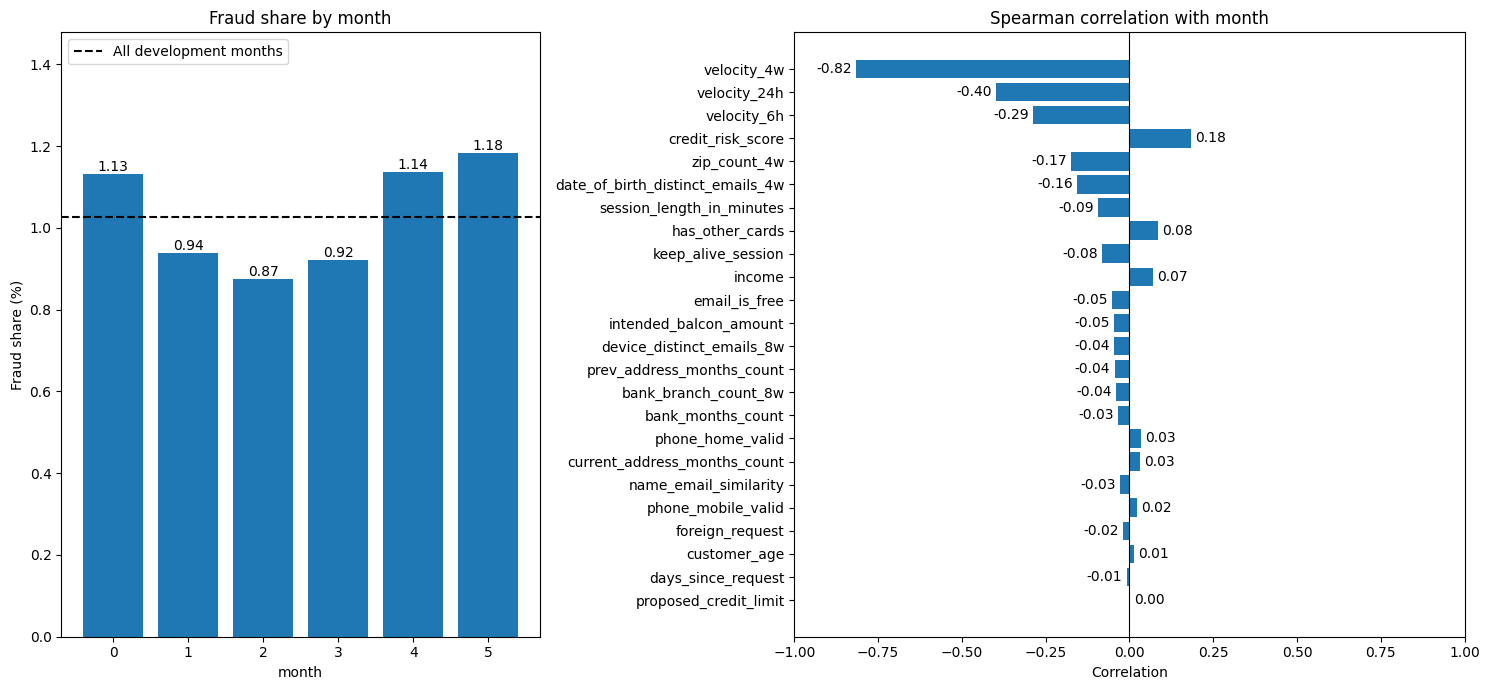

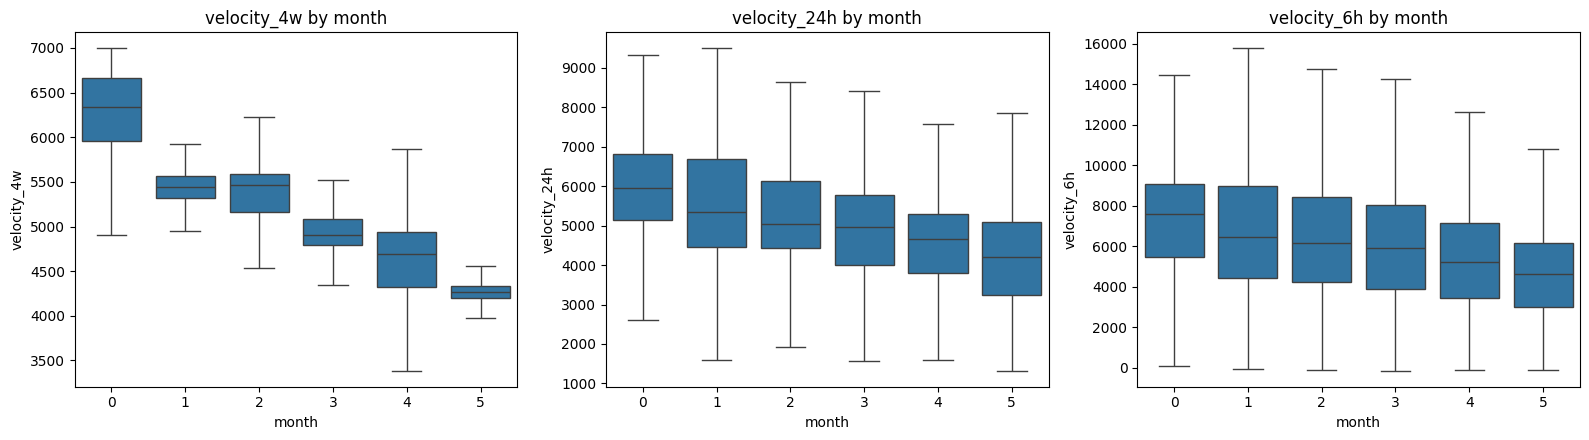

In [18]:
month_fraud = df_dev.groupby("month")["fraud_bool"].agg(Applications="size", Frauds="sum")
month_fraud["Fraud share (%)"] = month_fraud["Frauds"] / month_fraud["Applications"] * 100

display(month_fraud.round(2))

numeric_cols = df_dev.select_dtypes(include="number").columns.drop(["month", "fraud_bool", "device_fraud_count"])
month_corr = df_dev[numeric_cols].corrwith(df_dev["month"], method="spearman")
month_corr = month_corr.reindex(month_corr.abs().sort_values().index)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.4]})

axes[0].bar(month_fraud.index, month_fraud["Fraud share (%)"])
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].axhline(df_dev["fraud_bool"].mean() * 100, color="black", linestyle="--", label="All development months")
axes[0].set_ylim(0, month_fraud["Fraud share (%)"].max() * 1.25)
axes[0].legend(loc="upper left")
axes[0].set_title("Fraud share by month")
axes[0].set_xlabel("month")
axes[0].set_ylabel("Fraud share (%)")

axes[1].barh(month_corr.index, month_corr.values)
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", padding=3)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Spearman correlation with month")
axes[1].set_xlabel("Correlation")
axes[1].set_xlim(-1, 1)

plt.tight_layout()
plt.show()

strongest = month_corr.index[::-1][:3]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, column in zip(axes, strongest):
    sns.boxplot(data=df_dev, x="month", y=column, showfliers=False, ax=ax)
    ax.set_title(f"{column} by month")

plt.tight_layout()
plt.show()

**Q:** How does the fraud share develop over the six months? Is there a trend that a model could continue into later months?

**Q:** Which columns are related to `month`, and how strongly? What do the boxplots show about the three strongest ones?

**Q:** How much of the time information would remain in the data if the models did not get `month`?

### Almost constant columns

A column that has the same value in nearly all applications gives a model little to work with, unless its rare values go with a clearly different fraud share. To see whether other columns are almost constant like `source`, the table lists the input columns of `dev_prepared` sorted by how often their most common value occurs, from the most to the least constant column. For each column, it compares the fraud share of the most common value with the fraud share of all other values, and shows how many applications and frauds have one of the other values.

Two kinds of columns are left out: `device_fraud_count`, which has no other value and is removed anyway, and the `_missing` columns, whose relation to fraud was examined in the previous section.

In [19]:
missing_flags = [f"{column}_missing" for column in missing_columns]
checked_cols = dev_prepared.columns.drop(["fraud_bool", "device_fraud_count"] + missing_flags)

dev_fraud_bool = dev_prepared["fraud_bool"]
value_rows = []

for column in checked_cols:
    most_common = dev_prepared[column].value_counts().index[0]
    is_common = dev_prepared[column] == most_common
    value_rows.append({
        "Column": column,
        "Most common value": most_common,
        "Share of the most common value (%)": is_common.mean() * 100,
        "Fraud share with the most common value (%)": dev_fraud_bool[is_common].mean() * 100,
        "Applications with other values": (~is_common).sum(),
        "Frauds with other values": dev_fraud_bool[~is_common].sum(),
        "Fraud share with other values (%)": dev_fraud_bool[~is_common].mean() * 100,
    })

value_summary = pd.DataFrame(value_rows).set_index("Column")
display(value_summary.sort_values("Share of the most common value (%)", ascending=False).round(2))

,Most common value,Share of the most common value (%),Fraud share with the most common value (%),Applications with other values,Frauds with other values,Fraud share with other values (%)
Column,,,,,,
source,INTERNET,99.28,1.02,5737,80,1.39
foreign_request,0,97.40,1.00,20663,414,2.00
device_distinct_emails_8w,1,96.44,0.93,28323,1009,3.56
phone_mobile_valid,1,88.51,0.97,91319,1320,1.45
has_other_cards,0,77.58,1.20,178267,722,0.41
intended_balcon_amount,-1.0,73.84,1.22,207997,975,0.47
employment_status,CA,71.89,1.13,223446,1665,0.75
prev_address_months_count,-1,71.50,1.32,226566,634,0.28
proposed_credit_limit,200.0,61.50,0.68,306063,4846,1.58


**Q:** Which columns besides `source` are almost constant?

**Q:** In which of them do the rare values go with a clearly different fraud share, and how many frauds stand behind it?

**Q:** Is any of these columns so uninformative that removing it is justified?